In [1]:
import numpy as np
import pickle
import cv2
from os import listdir
from sklearn.preprocessing import LabelBinarizer
from keras.models import Sequential
from tensorflow.keras.layers import BatchNormalization
from keras.layers.convolutional import Conv2D
from keras.layers.convolutional import MaxPooling2D
from keras.layers.core import Activation, Flatten, Dropout, Dense
from keras import backend as K
from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from keras.preprocessing import image
from keras.preprocessing.image import img_to_array
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
EPOCHS = 20
INIT_LR = 1e-3
BS = 10
default_image_size = tuple((128, 128))
image_size = 0
directory_root = "E:\Dataset_Image"
width=128
height=128
depth=3

In [18]:
def convert_image_to_array(image_dir):
    try:
        image = cv2.imread(image_dir)
        if image is not None :
            image = cv2.resize(image, default_image_size)   
            return img_to_array(image)
        else :
            return np.array([])
    except Exception as e:
        print(f"Error : {e}")
        return None

In [19]:
image_list, label_list = [], []
try:
    print("[INFO] Loading images ...")
    root_dir = listdir(directory_root)    


    for fall_folder in root_dir:
            print(f"[INFO] Processing {fall_folder} ...")
            fall_image_list = listdir(f"{directory_root}/{fall_folder}/")
                

            for image in fall_image_list[:9000]:
                image_directory = f"{directory_root}/{fall_folder}/{image}"
                if image_directory.endswith(".jpg") == True or image_directory.endswith(".JPG") == True:
                    image_list.append(convert_image_to_array(image_directory))
                    label_list.append(fall_folder)
    print("[INFO] Image loading completed")  

except Exception as e:
    print(f"Error : {e}")

[INFO] Loading images ...
[INFO] Processing Fall ...
[INFO] Processing NonFall ...
[INFO] Image loading completed


In [20]:
image_size = len(image_list)
print(image_size)

11195


In [7]:
np_image_list = np.array(image_list, dtype=np.float16) / 225

In [8]:
label_binarizer = LabelBinarizer()
image_labels = label_binarizer.fit_transform(label_list)
pickle.dump(label_binarizer,open('label_transform.pkl', 'wb'))
n_classes = len(label_binarizer.classes_)

In [9]:
print("[INFO] Number of classes :", n_classes)
print(label_binarizer.classes_)


[INFO] Number of classes : 2
['Fall' 'NonFall']


In [10]:
print("[INFO] Spliting data to train, test")
x_train, x_test, y_train, y_test = train_test_split(np_image_list, image_labels, test_size=0.3, random_state = 12) 

[INFO] Spliting data to train, test


In [11]:
aug = ImageDataGenerator(
    featurewise_center=True,featurewise_std_normalization=True,
    rotation_range=20, width_shift_range=0.2,
    height_shift_range=0.2, shear_range=0.2, 
    horizontal_flip=True, validation_split=0.2)

In [12]:
model = Sequential()
inputShape = (height, width, depth)
chanDim = -1
if K.image_data_format() == "channels_first":
    inputShape = (depth, height, width)
    chanDim = 1
model.add(Conv2D(32, kernel_size=(3, 3), activation= "relu",input_shape=inputShape))
model.add(Conv2D(64,(3,3),activation="relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(64, (3, 3),activation= "relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Conv2D(128, (3, 3),activation= "relu"))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1,activation="sigmoid"))

In [13]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 conv2d_1 (Conv2D)           (None, 124, 124, 64)      18496     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 62, 62, 64)       0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 62, 62, 64)        0         
                                                                 
 conv2d_2 (Conv2D)           (None, 60, 60, 64)        36928     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 30, 30, 64)       0         
 2D)                                                    

In [14]:
#opt = Adam(lr=INIT_LR, decay=INIT_LR / EPOCHS)
# distribution
model.compile(loss="binary_crossentropy", optimizer='adam',metrics=["accuracy"])
# train the network
print("[INFO] training network...")

[INFO] training network...


In [15]:
history = model.fit_generator(
    aug.flow(x_train, y_train, batch_size=BS),
    validation_data=(x_test, y_test),
    steps_per_epoch=len(x_train) // BS,
    epochs=EPOCHS, verbose=1
    )

C:\Users\DELL\AppData\Local\Temp/ipykernel_3636/1273247788.py:1: UserWarning: `Model.fit_generator` is deprecated and will be removed in a future version. Please use `Model.fit`, which supports generators.
  history = model.fit_generator(
C:\Users\DELL\anaconda3\lib\site-packages\keras_preprocessing\image\image_data_generator.py:720: UserWarning: This ImageDataGenerator specifies `featurewise_center`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn('This ImageDataGenerator specifies '
C:\Users\DELL\anaconda3\lib\site-packages\keras_preprocessing\image\image_data_generator.py:728: UserWarning: This ImageDataGenerator specifies `featurewise_std_normalization`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn('This ImageDataGenerator specifies '


Epoch 1/20
783/783 [==============================] - 732s 930ms/step - loss: 0.4310 - accuracy: 0.8111 - val_loss: 0.2774 - val_accuracy: 0.8845
Epoch 2/20
783/783 [==============================] - 815s 1s/step - loss: 0.2590 - accuracy: 0.8786 - val_loss: 0.2143 - val_accuracy: 0.8997
Epoch 3/20
783/783 [==============================] - 742s 948ms/step - loss: 0.2236 - accuracy: 0.8845 - val_loss: 0.1759 - val_accuracy: 0.8997
Epoch 4/20
783/783 [==============================] - 660s 842ms/step - loss: 0.2019 - accuracy: 0.8902 - val_loss: 0.1745 - val_accuracy: 0.8967
Epoch 5/20
783/783 [==============================] - 525s 670ms/step - loss: 0.1894 - accuracy: 0.8920 - val_loss: 0.1750 - val_accuracy: 0.8955
Epoch 6/20
783/783 [==============================] - 457s 583ms/step - loss: 0.1911 - accuracy: 0.8943 - val_loss: 0.1511 - val_accuracy: 0.9172
Epoch 7/20
783/783 [==============================] - 504s 644ms/step - loss: 0.1860 - accuracy: 0.8968 - val_loss: 0.1325 - va

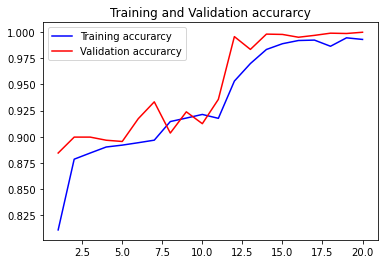

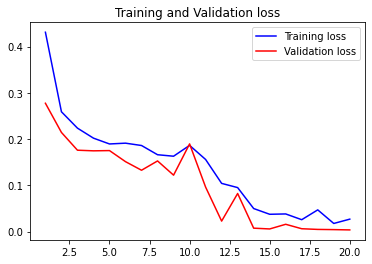

In [22]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(acc) + 1)
#Train and validation accuracy
plt.plot(epochs, acc, 'b', label='Training accurarcy')
plt.plot(epochs, val_acc, 'r', label='Validation accurarcy')
plt.title('Training and Validation accurarcy')
plt.legend()

plt.figure()
#Train and validation loss
plt.plot(epochs, loss, 'b', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and Validation loss')
plt.legend()
plt.show()

In [23]:
print("[INFO] Calculating model accuracy")
scores = model.evaluate(x_test, y_test)
print(f"Test Accuracy: {scores[1]*100}")

[INFO] Calculating model accuracy
105/105 [==============================] - 24s 230ms/step - loss: 0.0035 - accuracy: 0.9997
Test Accuracy: 99.97022747993469
